# Home Credit Scorecard Model
### Notebook 05 — Decision thresholds, business impact, explainability and recommendations (Steps 10–11)

Run order: `01` → `02` → `03` → `04` → **this notebook**. It uses the models and predictions saved by notebook 04 and
starts a fresh Python process. Runtime is about 12 minutes on one CPU, mostly the SHAP explanations, which are cached in
`data/processed/cv_cache/`.

**All money figures in this notebook are illustrative scenarios, not actual Home Credit results.**

In [1]:
import ctypes
import gc
import json
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import roc_auc_score

SEED = 42
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def find_project_root(start: Path) -> Path:
    """Project root = the folder containing src/build_dataset.py, searched upward from the notebook folder.
    Override with the HC_PROJECT_ROOT environment variable."""
    if os.environ.get("HC_PROJECT_ROOT"):
        return Path(os.environ["HC_PROJECT_ROOT"]).resolve()
    for folder in [start, *start.parents]:
        if (folder / "src" / "build_dataset.py").exists():
            return folder
    raise FileNotFoundError(
        f"Project root not found searching upward from {start}.\n"
        "Expected folder layout:\n"
        "  home-credit-scorecard-model/\n"
        "    notebooks/02_dataset_preprocessing.ipynb   <- this notebook\n"
        "    src/__init__.py, src/build_dataset.py, src/preprocessing.py\n"
        "    data/raw/   (the provided CSV files)\n"
        "Fix: unzip the complete project folder and open the notebook from its notebooks/ folder, "
        "or set HC_PROJECT_ROOT to the folder that contains src/.")


ROOT = find_project_root(Path.cwd().resolve())
for f in ["__init__.py", "build_dataset.py", "preprocessing.py"]:
    assert (ROOT / "src" / f).exists(), f"Missing {ROOT / 'src' / f} - copy the complete src/ folder"

# Package checks (clear messages instead of obscure errors later)
import re
_skl = tuple(int(x) for x in re.findall(r"\d+", sklearn.__version__)[:2])
assert _skl >= (1, 7), (
    f"scikit-learn {sklearn.__version__} found; 1.7 or newer is required. "
    "Run: pip install -U scikit-learn  (or: conda install -c conda-forge scikit-learn>=1.7)")
try:
    import pyarrow  # noqa: F401  (needed for the .parquet dataset files)
except ImportError as e:
    raise ImportError("pyarrow is required. Run: pip install pyarrow  (or: conda install -c conda-forge pyarrow)") from e

DATA_CANDIDATES = [os.environ.get("HC_DATA_DIR"), ROOT / "data" / "raw", Path("/mnt/user-data/uploads")]
DATA_DIR = next((Path(c) for c in DATA_CANDIDATES if c and (Path(c) / "application_train.csv").exists()), None)
assert DATA_DIR is not None, "application_train.csv not found - set HC_DATA_DIR or place files in data/raw"
REPORTS, FIG, PROCESSED = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "data" / "processed"
assert (PROCESSED / "split_assignment.csv").exists(), "Run notebook 01 first: it creates the validation split"


def release_memory():
    # Free Python objects and hand unused heap memory back to the operating system
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError:
        pass


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print("Project root:", ROOT)
print("DATA_DIR:", DATA_DIR)
import warnings
for f in ["abt_train.parquet", "abt_test.parquet", "data_dictionary.csv"]:
    assert (PROCESSED / f).exists(), f"{f} not found - run notebook 02 first (it builds the modelling dataset)"

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0
Project root: /mnt/user-data/outputs/home-credit-scorecard-model
DATA_DIR: /mnt/user-data/uploads


In [2]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import joblib
warnings.filterwarnings("ignore", message="IProgress not found")      # cosmetic progress-bar notice from shap's import
import shap
from sklearn.metrics import roc_auc_score
from src.evaluation import calibration_table, expected_calibration_error, ranking_metrics

MODELS, CACHE = ROOT / "models", PROCESSED / "cv_cache"
CACHE.mkdir(exist_ok=True)
for f in [MODELS / "selected_model.joblib", MODELS / "challenger_model.joblib", PROCESSED / "pred_dev_oof.parquet",
          PROCESSED / "pred_holdout.parquet", PROCESSED / "scoring_predictions.csv"]:
    assert f.exists(), f"{f.name} not found - run notebook 04 first"
sel, ch = joblib.load(MODELS / "selected_model.joblib"), joblib.load(MODELS / "challenger_model.joblib")
oof = pd.read_parquet(PROCESSED / "pred_dev_oof.parquet")       # development, out-of-fold (policy design)
hold = pd.read_parquet(PROCESSED / "pred_holdout.parquet")      # locked holdout (one confirmation)
scoring = pd.read_csv(PROCESSED / "scoring_predictions.csv")    # unlabelled scoring set (stability only)
print(f"Selected: {sel['name']} | challenger: {ch['name']}")
print(f"Development (out-of-fold): {len(oof):,} loans, TARGET rate {100 * oof.TARGET.mean():.2f}% | "
      f"holdout: {len(hold):,} | scoring set: {len(scoring):,}")
print(f"Calibration check (development): mean predicted {100 * oof.p_selected.mean():.2f}% vs observed "
      f"{100 * oof.TARGET.mean():.2f}%, ECE {expected_calibration_error(oof.TARGET, oof.p_selected):.4f}")

Selected: Gradient boosting (tuned) | challenger: Logistic Regression (tuned, C=0.01)
Development (out-of-fold): 246,008 loans, TARGET rate 8.07% | holdout: 61,503 | scoring set: 48,744
Calibration check (development): mean predicted 8.07% vs observed 8.07%, ECE 0.0005


## 18. Step 10 — Decision thresholds and business impact

A predicted probability is **not** a credit decision. A policy turns it into one:

> **Decline** if the predicted probability of payment difficulty is at or above a threshold *t*; otherwise **approve**.
> (Section 18.4 adds a manual-review band.)

**The baseline.** Every loan in this data was approved under the current process. The natural baseline is therefore
**"approve all"**, with an observed payment-difficulty rate of 8.07%. Every policy below is evaluated as a change from that
baseline: which of these historically approved loans the model would have declined. Two consequences follow:
* **Selection bias.** Applicants who were rejected in the past are not in the data. The analysis says nothing about approving
  them, and the effect on the full through-the-door population can differ (Step 1).
* **Development data only.** The policy is designed on development out-of-fold predictions. The holdout confirms it once,
  in 18.5.

**The error types.**
* **False approval:** an approved loan with `TARGET = 1`.
* **False rejection:** a declined loan with `TARGET = 0`.

The rates are scaled per 10,000 applications for readability.

In [3]:
y, p, p_ch = oof.TARGET.to_numpy(), oof.p_selected.to_numpy(), oof.p_challenger.to_numpy()
credit = oof.AMT_CREDIT.to_numpy()

def policy_stats(y, p, t, credit=None):
    dec = p >= t
    n, nd = len(y), dec.sum()
    bad, good = y == 1, y == 0
    out = {"threshold": t, "decline_pct": 100 * nd / n, "approval_pct": 100 * (1 - nd / n),
           "bad_rate_approved_pct": 100 * y[~dec].mean() if (~dec).any() else np.nan,
           "bad_rate_declined_pct": 100 * y[dec].mean() if nd else np.nan,
           "recall_bad_caught_pct": 100 * (dec & bad).sum() / bad.sum(),
           "false_approvals_per_10k": 1e4 * (~dec & bad).sum() / n,
           "false_rejections_per_10k": 1e4 * (dec & good).sum() / n,
           "goods_declined_per_bad_caught": (dec & good).sum() / max((dec & bad).sum(), 1)}
    if credit is not None:
        out["bad_exposure_avoided_pct"] = 100 * credit[dec & bad].sum() / credit[bad].sum()
    return out

decline_grid = [0, 2.5, 5, 7.5, 10, 15, 20, 25, 30]
rows = []
for q in decline_grid:
    for model, pp in [("selected", p), ("challenger", p_ch)]:
        t = np.inf if q == 0 else np.quantile(pp, 1 - q / 100)
        rows.append({"model": model, "target_decline_pct": q, **policy_stats(y, pp, t, credit)})
strategy = pd.DataFrame(rows)
strategy.to_csv(REPORTS / "step10_strategy_table.csv", index=False)
show = ["target_decline_pct", "threshold", "approval_pct", "bad_rate_approved_pct", "bad_rate_declined_pct",
        "recall_bad_caught_pct", "false_approvals_per_10k", "false_rejections_per_10k", "goods_declined_per_bad_caught",
        "bad_exposure_avoided_pct"]
print("Selected model - decline the riskiest q% of applicants (development, out-of-fold):")
display(strategy[strategy.model == "selected"][show].round(3))

Selected model - decline the riskiest q% of applicants (development, out-of-fold):


,target_decline_pct,threshold,approval_pct,bad_rate_approved_pct,bad_rate_declined_pct,recall_bad_caught_pct,false_approvals_per_10k,false_rejections_per_10k,goods_declined_per_bad_caught,bad_exposure_avoided_pct
0,0.0,inf,100.000,8.073,NaN,0.000,807.291,0.000,0.000,0.000
2,2.5,0.322,97.486,7.143,44.139,13.746,696.319,140.443,1.266,12.120
4,5.0,0.267,94.942,6.551,36.650,22.961,621.931,320.396,1.729,20.317
6,7.5,0.227,92.277,6.059,32.135,30.740,559.128,524.089,2.112,27.519
8,10.0,0.191,89.859,5.669,29.378,36.903,509.374,716.156,2.404,33.321
10,15.0,0.152,84.999,4.999,25.488,47.362,424.946,1117.728,2.923,43.346
12,20.0,0.130,79.863,4.437,22.492,56.103,354.379,1560.762,3.446,51.990
14,25.0,0.106,74.911,3.944,20.400,63.399,295.478,1997.090,3.902,59.435
16,30.0,0.089,69.776,3.514,18.598,69.627,245.195,2460.326,4.377,65.974


**Result: the trade-off in numbers** (per 10,000 historically approved applications).
* **Decline the riskiest 5%:** the payment-difficulty rate among approved loans falls from 8.073% to 6.551%, and 22.961% of all
  difficulty cases are caught. That costs 320 false rejections, about 1.7 good applicants declined per risky one.
* **Decline the riskiest 10%:** the approved book's rate falls to 5.669%, 36.903% of cases are caught, and 2.4 good applicants
  are declined per risky one.
* **Declining more has diminishing returns.** At 30% declined the approved rate is 3.514%, but 4.4 good applicants are lost
  for every risky one caught.

This is the core credit-policy tension: **every extra percentage point of risk removed costs progressively more
creditworthy customers.** A lower threshold misses fewer risky applicants but flags more applicants who would have repaid.

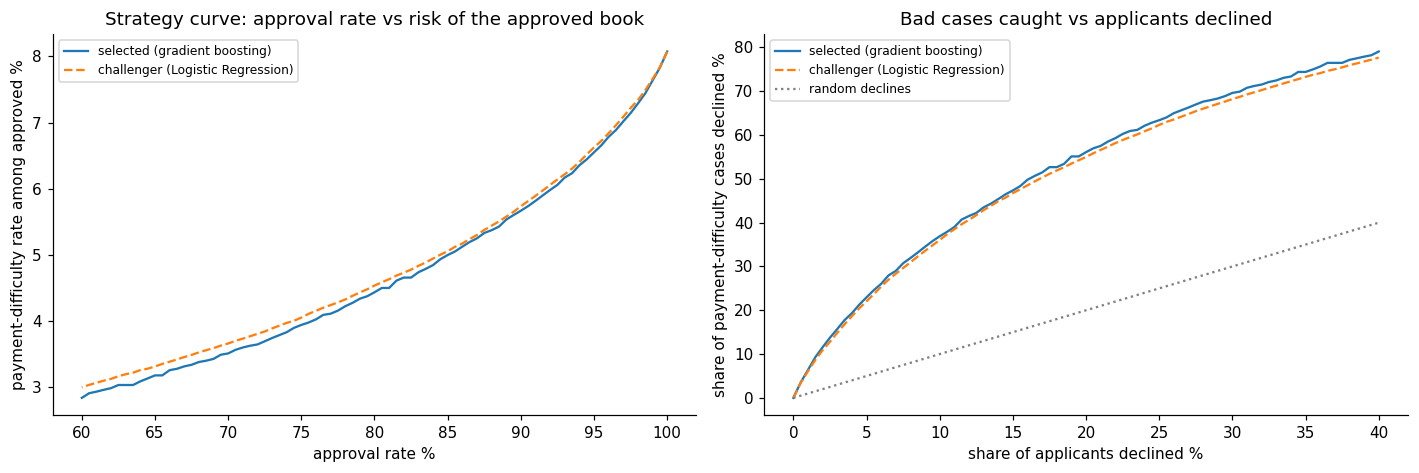

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
qs = np.linspace(0, 40, 81)
for model, pp, st in [("selected (gradient boosting)", p, "-"), ("challenger (Logistic Regression)", p_ch, "--")]:
    br = [policy_stats(y, pp, np.inf if q == 0 else np.quantile(pp, 1 - q / 100))["bad_rate_approved_pct"] for q in qs]
    rc = [policy_stats(y, pp, np.inf if q == 0 else np.quantile(pp, 1 - q / 100))["recall_bad_caught_pct"] for q in qs]
    ax[0].plot(100 - qs, br, st, label=model)
    ax[1].plot(qs, rc, st, label=model)
ax[1].plot(qs, qs, ":", c="grey", label="random declines")
ax[0].set(xlabel="approval rate %", ylabel="payment-difficulty rate among approved %",
          title="Strategy curve: approval rate vs risk of the approved book")
ax[1].set(xlabel="share of applicants declined %", ylabel="share of payment-difficulty cases declined %",
          title="Bad cases caught vs applicants declined")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "10_strategy_curves.png", bbox_inches="tight"); plt.show()

The figure shows the full trade-off for both models across all approval rates. Both are far better than random declines
(the dotted diagonal). Which model is better is quantified in money terms at the operating points in Section 18.3.

### 18.2 Unit economics and illustrative cost scenarios
No actual Home Credit pricing, funding costs or loss data are available, so every money figure here is an **ILLUSTRATIVE
SCENARIO, not an actual Home Credit result**. Amounts are in the currency units of `AMT_CREDIT` in the provided data.

For each loan with credit amount *C*:

| Outcome | Effect versus "approve all" | Parameter |
|---|---|---|
| Approve, `TARGET = 0` | Earns net contribution *m·C* (in the baseline too, so no change) | *m*: lifetime net margin of a repaid loan |
| Approve, `TARGET = 1` | Loses *L·C* (in the baseline too, so no change) | *L*: expected loss on a payment-difficulty loan = P(default given difficulty) × loss given default |
| Decline, `TARGET = 1` | **+L·C** (loss avoided) | |
| Decline, `TARGET = 0` | **−m·C** (margin forgone: a false rejection) | |

So **Δprofit(policy) = Σ declined bad L·C − Σ declined good m·C**. Each loan's principal, revenue and loss enters once,
so nothing is double-counted. Equivalently, the expected cost

> **Expected cost = Σ false approvals × L·C + Σ false rejections × m·C**

differs from Δprofit only by a constant (the cost of the baseline), so minimising one maximises the other.

**Scenario grid.** *m* ∈ {5%, 10%, 15%}, *L* ∈ {15%, 30%, 45%}. The central case is *m* = 10%, *L* = 30%. *L* is deliberately well below 100%:
`TARGET = 1` means early payment difficulty, and many such loans cure (Step 1).

Because both effects scale with *C*, decision theory gives the break-even probability **p\* = m / (m + L)**. With calibrated
probabilities, declining exactly when *p* ≥ *p\** maximises the expected Δprofit. The empirical optimum below is compared with this.

In [5]:
def delta_profit(y, p, credit, t, m, L):
    dec = p >= t
    return float((L * credit[dec & (y == 1)]).sum() - (m * credit[dec & (y == 0)]).sum())

t_grid = np.unique(np.quantile(p, 1 - np.arange(0, 60.5, 0.5) / 100))     # thresholds declining 0-60% of applicants
M_GRID, L_GRID, CENTRAL = [0.05, 0.10, 0.15], [0.15, 0.30, 0.45], (0.10, 0.30)
n = len(y)
rows = []
for m in M_GRID:
    for L in L_GRID:
        base = float((m * credit[y == 0]).sum() - (L * credit[y == 1]).sum())
        gains = np.array([delta_profit(y, p, credit, t, m, L) for t in t_grid])
        i = int(np.argmax(gains))
        t_opt = t_grid[i]
        p_star = m / (m + L)
        rows.append({"margin_m": m, "loss_L": L, "break_even_p_star": p_star, "empirical_best_threshold": t_opt,
                     "decline_pct": 100 * (p >= t_opt).mean(),
                     "bad_rate_approved_pct": 100 * y[p < t_opt].mean(),
                     "delta_profit_per_1k_applications": 1e3 * gains[i] / n,
                     "delta_profit_at_p_star_per_1k": 1e3 * delta_profit(y, p, credit, p_star, m, L) / n,
                     "baseline_profit_per_1k_applications": 1e3 * base / n,
                     "delta_profit_pct_of_baseline": 100 * gains[i] / abs(base) if base else np.nan})
scen = pd.DataFrame(rows)
scen.to_csv(REPORTS / "step10_cost_scenarios.csv", index=False)
print("ILLUSTRATIVE scenarios (development, out-of-fold). Money per 1,000 applications, in AMT_CREDIT currency units.")
display(scen.round(4))

ILLUSTRATIVE scenarios (development, out-of-fold). Money per 1,000 applications, in AMT_CREDIT currency units.


,margin_m,loss_L,break_even_p_star,empirical_best_threshold,decline_pct,bad_rate_approved_pct,delta_profit_per_1k_applications,delta_profit_at_p_star_per_1k,baseline_profit_per_1k_applications,delta_profit_pct_of_baseline
0,0.05,0.15,0.2500,0.2514,5.5397,6.4433,5.976037e+05,5.945898e+05,2.096599e+07,2.8503
1,0.05,0.30,0.1429,0.1371,18.0100,4.6593,2.961138e+06,2.948412e+06,1.421530e+07,20.8306
2,0.05,0.45,0.1000,0.0992,28.4235,3.6494,6.738257e+06,6.708542e+06,7.464607e+06,90.2694
3,0.10,0.15,0.4000,0.3904,2.0353,7.2871,1.475810e+05,1.465528e+05,4.868267e+07,0.3031
4,0.10,0.30,0.2500,0.2514,5.5397,6.4433,1.195207e+06,1.189180e+06,4.193198e+07,2.8503
5,0.10,0.45,0.1818,0.1898,10.5334,5.6030,3.126562e+06,3.105322e+06,3.518129e+07,8.8870
6,0.15,0.15,0.5000,0.5058,0.5081,7.8277,4.371479e+04,4.274261e+04,7.639935e+07,0.0572
7,0.15,0.30,0.3333,0.3217,2.5141,7.1428,6.006675e+05,6.028197e+05,6.964866e+07,0.8624
8,0.15,0.45,0.2500,0.2514,5.5397,6.4433,1.792811e+06,1.783769e+06,6.289797e+07,2.8503


**Result** (illustrative scenarios).
* **The probabilities can be used for pricing decisions.** The empirically best threshold sits very close to the theoretical
  break-even point *p\* = m/(m+L)* in every scenario (central: 0.2514 versus 0.25). Using *p\** directly gives almost the same
  Δprofit. This is direct evidence that the recalibrated probabilities can be used at face value.
* **The policy depends mainly on the loss-to-margin ratio.** Scenarios with the same L/m (for example 5%/15%, 10%/30% and
  15%/45%) give the same threshold (decline 5.5397%) and the same relative gain, 2.8503% of baseline profit.
* **The central scenario** (m = 10%, L = 30%) declines 5.5397% of applicants, lowers the approved book's difficulty rate to
  6.4433%, and adds about 1.2 million currency units per 1,000 applications, which is 2.85% of the baseline profit.
* **The value of the model rises with the loss rate.** With high losses and thin margins (m = 5%, L = 45%) it is worth declining
  28.4235% of applicants, and Δprofit reaches 90.2694% of baseline profit. With low losses and fat margins (m = 15%, L = 15%)
  almost nobody should be declined (0.5081%).

**Implication.** The right cut-off is a **business parameter, not a model property**. Finance and Risk need to supply actual
margins and loss rates, and the threshold should follow from *p\* = m/(m+L)*.

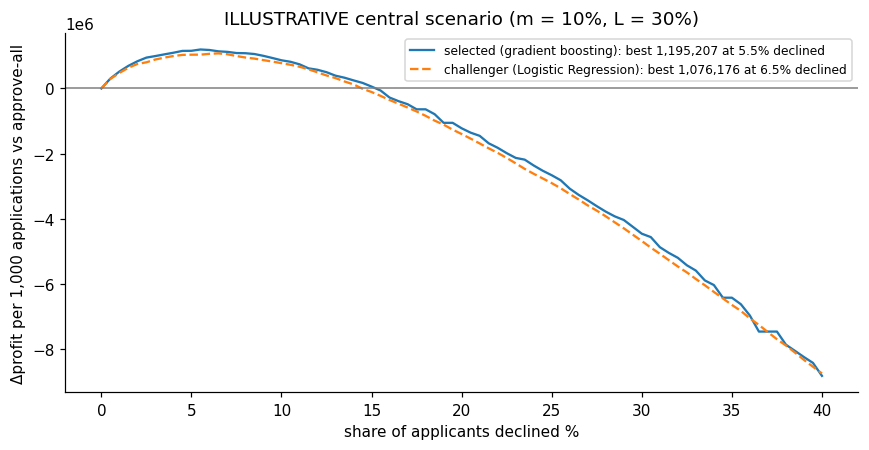

Value of the selected model over the challenger at their own best thresholds: 119,032 per 1,000 applications (central scenario)
Central-scenario decline threshold p* = 0.250


In [6]:
m0, L0 = CENTRAL
qs = np.arange(0, 40.5, 0.5)
fig, ax = plt.subplots(figsize=(8, 4.2))
best = {}
for model, pp, st in [("selected (gradient boosting)", p, "-"), ("challenger (Logistic Regression)", p_ch, "--")]:
    ts = [np.inf if q == 0 else np.quantile(pp, 1 - q / 100) for q in qs]
    g = np.array([1e3 * delta_profit(y, pp, credit, t, m0, L0) / n for t in ts])
    best[model] = (qs[int(np.argmax(g))], g.max(), ts[int(np.argmax(g))])
    ax.plot(qs, g, st, label=f"{model}: best {g.max():,.0f} at {qs[int(np.argmax(g))]:.1f}% declined")
ax.axhline(0, c="grey", lw=1)
ax.set(xlabel="share of applicants declined %", ylabel="Δprofit per 1,000 applications vs approve-all",
       title=f"ILLUSTRATIVE central scenario (m = {m0:.0%}, L = {L0:.0%})")
ax.legend(fontsize=8); plt.tight_layout(); fig.savefig(FIG / "10_central_scenario_profit.png", bbox_inches="tight"); plt.show()
gap = best["selected (gradient boosting)"][1] - best["challenger (Logistic Regression)"][1]
print(f"Value of the selected model over the challenger at their own best thresholds: {gap:,.0f} per 1,000 applications "
      f"(central scenario)")
T_DECLINE = m0 / (m0 + L0)          # break-even threshold of the central scenario
print(f"Central-scenario decline threshold p* = {T_DECLINE:.3f}")

At their own best thresholds in the central scenario, the selected model adds **119,032 currency units per 1,000
applications more than the challenger** (illustrative). The 0.0068 ROC-AUC advantage from Step 9 therefore has tangible business
value, in addition to being statistically consistent.

### 18.4 A three-band policy: approve, review, decline
A hard cut-off forces an automatic decision on borderline applicants. A **manual-review band** just below the decline
threshold can add verification instead: income documents, employment checks or a lower limit. Here the band covers the
next 10% of applicants by risk below the central-scenario threshold. Review costs are unknown, so the band is described
rather than priced.

In [7]:
share_above = (p >= T_DECLINE).mean()
T_REVIEW = float(np.quantile(p, 1 - min(share_above + 0.10, 0.99)))
band = np.select([p >= T_DECLINE, p >= T_REVIEW], ["3 decline", "2 review"], "1 approve")
bands = (pd.DataFrame({"band": band, "y": y, "credit": credit, "p": p})
         .groupby("band").agg(applications_pct=("y", lambda s: 100 * len(s) / n), observed_bad_rate_pct=("y", lambda s: 100 * s.mean()),
                              mean_predicted_pct=("p", lambda s: 100 * s.mean()),
                              share_of_all_bad_cases_pct=("y", lambda s: 100 * s.sum() / y.sum()),
                              share_of_credit_pct=("credit", lambda s: 100 * s.sum() / credit.sum())))
print(f"Thresholds: review from p >= {T_REVIEW:.3f}, decline from p >= {T_DECLINE:.3f}")
display(bands.round(2))
bands.to_csv(REPORTS / "step10_three_band_policy.csv")

Thresholds: review from p >= 0.144, decline from p >= 0.250


,applications_pct,observed_bad_rate_pct,mean_predicted_pct,share_of_all_bad_cases_pct,share_of_credit_pct
band,,,,,
1 approve,84.06,4.90,4.88,51.00,86.24
2 review,10.21,18.84,18.90,23.84,9.02
3 decline,5.73,35.45,35.62,25.16,4.75


**Result: three-band policy** (central scenario).
* **Approve (84.06%).** The difficulty rate is 4.90%; these loans carry 86.24% of the credit volume.
* **Review (10.21%).** The difficulty rate is 18.84%, more than twice the portfolio rate, and the band holds 23.84% of all difficulty
  cases. These applicants are neither clearly safe nor clearly unprofitable, so targeted verification or a reduced
  limit is worth more than an automatic decision.
* **Decline (5.73%).** The difficulty rate is 35.45%, and the band holds 25.16% of all difficulty cases but only 4.75% of credit volume.

Predicted and observed rates agree within each band (4.88% versus 4.90%, 18.90% versus 18.84%, 35.62% versus 35.45%), so the bands mean what they
say.

### 18.5 One-time confirmation on the holdout, and what the scoring set implies
The thresholds above were fixed on development data. They are now applied unchanged to the holdout, which is used once for
this confirmation, and to the unlabelled scoring set (approval mix only).

In [8]:
yh, ph, ph_ch, hold_credit = hold.TARGET.to_numpy(), hold.p_selected.to_numpy(), hold.p_challenger.to_numpy(), hold.AMT_CREDIT.to_numpy()
conf = []
for name, yy, pp, cc, t in [("development (out-of-fold)", y, p, credit, T_DECLINE), ("holdout", yh, ph, hold_credit, T_DECLINE),
                            ("holdout - challenger at its own best threshold", yh, ph_ch, hold_credit,
                             best["challenger (Logistic Regression)"][2])]:
    st = policy_stats(yy, pp, t, cc)
    conf.append({"data": name, "threshold": t, "decline_pct": st["decline_pct"],
                 "bad_rate_approved_pct": st["bad_rate_approved_pct"], "bad_rate_declined_pct": st["bad_rate_declined_pct"],
                 "recall_bad_caught_pct": st["recall_bad_caught_pct"],
                 "delta_profit_per_1k_central": 1e3 * delta_profit(yy, pp, cc, t, m0, L0) / len(yy)})
conf = pd.DataFrame(conf).set_index("data")
conf.to_csv(REPORTS / "step10_holdout_confirmation.csv")
display(conf.round(3))
ps = scoring.p_selected.to_numpy()
print(f"Scoring set (no labels): {100 * (ps >= T_DECLINE).mean():.2f}% would be declined and "
      f"{100 * ((ps >= T_REVIEW) & (ps < T_DECLINE)).mean():.2f}% reviewed, versus "
      f"{100 * (p >= T_DECLINE).mean():.2f}% and {100 * ((p >= T_REVIEW) & (p < T_DECLINE)).mean():.2f}% in development; "
      f"mean predicted risk {100 * ps.mean():.2f}% vs {100 * p.mean():.2f}%")

,threshold,decline_pct,bad_rate_approved_pct,bad_rate_declined_pct,recall_bad_caught_pct,delta_profit_per_1k_central
data,,,,,,
development (out-of-fold),0.250,5.729,6.409,35.455,25.161,1189179.571
holdout,0.250,5.624,6.319,37.496,26.123,1393108.885
holdout - challenger at its own best threshold,0.232,6.444,6.270,34.242,27.331,1145683.772


Scoring set (no labels): 5.07% would be declined and 10.04% reviewed, versus 5.73% and 10.21% in development; mean predicted risk 7.78% vs 8.07%


**Holdout confirmation (used once).**
* **The policy holds on new loans.** At the same threshold (0.250) it declines 5.624% of holdout applicants (5.729% in development),
  and the approved book's difficulty rate is 6.319% versus 6.409%.
* **The holdout gain is higher.** Central-scenario Δprofit is about 1.39 million per 1,000 applications on the holdout versus
  1.19 million in development; the holdout's declined group is somewhat riskier (37.496% versus 35.455%).
* **The challenger still trails.** At its own best threshold it delivers less on the holdout as well (about 1.15 million).
* **The scoring set would see a slightly lower decline rate:** 5.07% declined and 10.04% reviewed, with mean predicted risk
  7.78% versus 8.07%. This is consistent with its smaller share of revolving loans and its different feature distributions (Step 5).

## 19. Step 11 — Explainability, risk segments, fairness checks and recommendations

### 19.1 Validating the explanation method first
SHAP values explain a prediction as a sum of feature contributions. They are only usable for reason codes if they **add up**
exactly to the model's output. The usual fast method (TreeExplainer) was tested on the selected model and failed this check.
A small experiment, repeated below, isolates the cause: TreeExplainer is exact for gradient boosting *without* native
categorical splits and wrong *with* them. The selected model uses native categorical splits (Step 4), so a model-agnostic
**permutation explainer** is used instead. It is additive by construction, and this is verified.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
rng = np.random.default_rng(SEED)
Xs = pd.DataFrame({"a": rng.normal(size=4000), "b": rng.normal(size=4000), "c": rng.integers(0, 8, 4000).astype(float)})
ys = ((Xs.a + (Xs.c % 3 == 0) + rng.normal(size=4000)) > 1).astype(int)
for cat in [False, True]:
    mdl = HistGradientBoostingClassifier(max_iter=50, categorical_features=[False, False, cat], random_state=0).fit(Xs, ys)
    ex = shap.TreeExplainer(mdl)
    err = np.max(np.abs(np.asarray(ex.shap_values(Xs)).sum(1) + np.ravel(ex.expected_value)[0] - mdl.decision_function(Xs)))
    print(f"TreeExplainer, native categorical splits = {cat}: max additivity error {err:.4f}")

abt = pd.read_parquet(PROCESSED / "abt_train.parquet")
hold_X = abt[abt.fold == -1].drop(columns=["fold"]).reset_index(drop=True)
dev_X = abt[abt.fold >= 0].drop(columns=["fold"]).reset_index(drop=True)
del abt
release_memory()
pipe, cal = sel["model"], sel["calibrator"]
N_EXPLAIN, N_BACKGROUND = 400, 100
sample = hold_X.sample(N_EXPLAIN, random_state=SEED).reset_index(drop=True)
background = dev_X.sample(N_BACKGROUND, random_state=SEED)
Xt = pipe[0].transform(sample.drop(columns=["TARGET"]))
Bt = pipe[0].transform(background.drop(columns=["TARGET"]))
feat_names = list(pipe[0].get_feature_names_out())
f_raw = pipe[-1].decision_function          # explained in log-odds of the (pre-calibration) model; calibration is monotone

key = joblib.hash((pipe, Xt, Bt))
path = CACHE / f"shap_{key}.joblib"
if path.exists():
    sv, base_val = joblib.load(path)
    print("Permutation SHAP values loaded from cache")
else:
    t0 = time.time()
    ex = shap.PermutationExplainer(f_raw, shap.maskers.Independent(Bt, max_samples=N_BACKGROUND))
    e = ex(Xt, max_evals=2 * Xt.shape[1] + 1, silent=True)
    sv, base_val = e.values, e.base_values
    joblib.dump((sv, base_val), path)
    print(f"Permutation SHAP for {N_EXPLAIN} holdout applicants computed in {time.time() - t0:.0f}s")
add_err = float(np.max(np.abs(sv.sum(1) + base_val - f_raw(Xt))))
print(f"Permutation explainer, selected model: max additivity error {add_err:.2e}")
assert add_err < 1e-6

TreeExplainer, native categorical splits = False: max additivity error 0.0000


TreeExplainer, native categorical splits = True: max additivity error 9.9215


Permutation SHAP values loaded from cache
Permutation explainer, selected model: max additivity error 7.99e-15


**Result.** The experiment reproduces the cause: TreeExplainer is exact without native categorical splits (error 0.0000) and
wrong with them (error 9.9215). The permutation explainer reproduces the selected model's output exactly (maximum error
7.99e-15). **All explanations below are therefore exact decompositions** of the model's log-odds for these 400 applicants.

### 19.2 Global risk drivers
Three views are compared: mean absolute SHAP value for the selected model (400 holdout applicants), permutation
importance from notebook 04 (15,000 validation rows per fold, 2 folds), and the size of the challenger Logistic Regression's
coefficients (summed over each feature's one-hot, bin and missing-indicator terms; inputs are standardised). Agreement
across three methods and two model families makes a driver credible; any single method can mislead.

In [10]:
shap_imp = pd.Series(np.abs(sv).mean(0), index=feat_names).sort_values(ascending=False)
perm = pd.read_csv(REPORTS / "step7_permutation_importance.csv", index_col=0)["mean"]
lr = ch["model"]
lr_names, lr_coef = lr[0].get_feature_names_out(), lr[-1].coef_[0]
feats = sorted(sel["features"], key=len, reverse=True)

def original(name):
    rest = name.split("__", 1)[1].replace("missingindicator_", "")
    return next((f for f in feats if rest == f or rest.startswith(f + "_")), rest)

lr_imp = pd.Series(np.abs(lr_coef), index=[original(nm) for nm in lr_names]).groupby(level=0).sum()
drivers = pd.DataFrame({"mean_abs_shap": shap_imp, "permutation_importance": perm, "lr_abs_coef_sum": lr_imp})
for c in drivers.columns:
    drivers[c.replace("mean_abs_shap", "shap").replace("permutation_importance", "perm").replace("lr_abs_coef_sum", "lr") + "_rank"] = \
        drivers[c].rank(ascending=False)
drivers = drivers.sort_values("mean_abs_shap", ascending=False)
drivers.to_csv(REPORTS / "step11_global_drivers.csv")
display(drivers.head(20).round(4))
top20 = drivers.head(20).index
print(f"Of the top 20 SHAP drivers, {int((drivers.loc[top20, 'perm_rank'] <= 30).sum())} are in the permutation top 30 "
      f"and {int((drivers.loc[top20, 'lr_rank'] <= 30).sum())} in the Logistic Regression top 30. "
      f"Spearman rank correlation SHAP vs permutation (all features): "
      f"{drivers[['mean_abs_shap', 'permutation_importance']].corr(method='spearman').iloc[0, 1]:.3f}")

,mean_abs_shap,permutation_importance,lr_abs_coef_sum,shap_rank,perm_rank,lr_rank
EXT_SOURCE_2,0.2808,0.0355,0.4141,1.0,1.0,10.0
EXT_SOURCE_3,0.2627,0.0323,0.5449,2.0,2.0,7.0
EXT_SOURCE_1,0.1799,0.0147,0.2606,3.0,3.0,17.0
ORGANIZATION_TYPE,0.1299,0.0034,3.4178,4.0,7.0,1.0
APP_CREDIT_TO_GOODS,0.1051,0.0024,0.5471,5.0,8.0,6.0
AMT_ANNUITY,0.0913,0.0035,0.0119,6.0,6.0,146.0
APP_CREDIT_TERM,0.0869,0.0048,1.0603,7.0,4.0,3.0
POS_REMAINING_INSTALMENTS,0.0819,0.0041,0.1839,8.0,5.0,37.0
OCCUPATION_TYPE,0.0795,0.0018,1.6496,9.0,11.0,2.0
NAME_EDUCATION_TYPE,0.0685,0.0020,0.5087,10.0,10.0,8.0


Of the top 20 SHAP drivers, 19 are in the permutation top 30 and 10 in the Logistic Regression top 30. Spearman rank correlation SHAP vs permutation (all features): 0.740


**Result: global drivers.**
* **The external scores dominate in every view.** `EXT_SOURCE_2`, `_3` and `_1` are ranks 1–3 by both SHAP and permutation
  importance.
* **Next come application and product characteristics:** organisation type, credit-to-goods ratio, annuity, implied term,
  occupation and education. History features follow: remaining POS instalments, previous loan terms and amount cuts,
  bureau debt ratio, recent late instalments and bureau activity.
* **The methods agree well.** 19 of the top 20 SHAP drivers are in the permutation top 30, and the rank correlation across all
  features is 0.740.
* **Agreement with Logistic Regression is weaker** (10 of 20 in its top 30). This is expected: the linear model spreads
  categorical effects over many one-hot terms (organisation type ranks first there) and cannot use interactions.

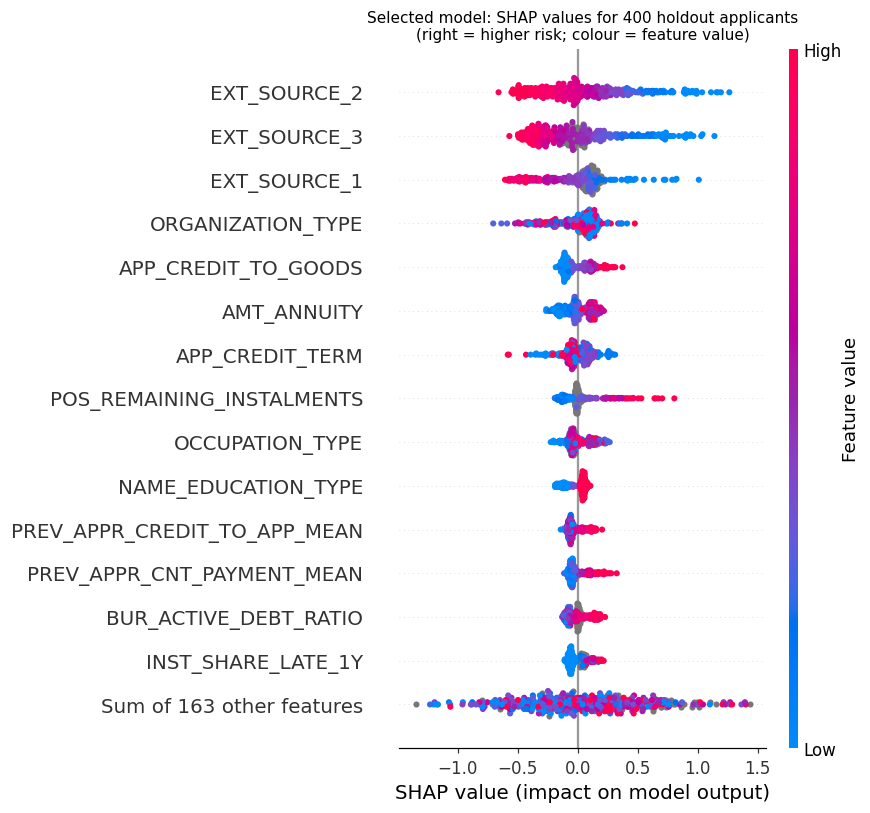

In [11]:
expl = shap.Explanation(values=sv, base_values=base_val, data=Xt, feature_names=feat_names)
plt.figure()
shap.plots.beeswarm(expl, max_display=15, show=False)
plt.title("Selected model: SHAP values for 400 holdout applicants\n(right = higher risk; colour = feature value)", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "11_shap_beeswarm.png", bbox_inches="tight"); plt.show()

In [12]:
num_idx = [i for i, f in enumerate(feat_names) if f not in sel["model"][0].transformers_[1][2]]   # numeric inputs only
rows = []
for f in drivers.head(25).index:
    i = feat_names.index(f)
    if i not in num_idx:
        continue
    x, s = Xt[:, i], sv[:, i]
    ok = ~np.isnan(x)
    rho = pd.Series(x[ok]).corr(pd.Series(s[ok]), method="spearman") if ok.sum() > 20 else np.nan
    lr_terms = [j for j, nm in enumerate(lr_names) if nm in (f"num__{f}", f"num_log__{f}")]
    lr_sign = np.sign(lr_coef[lr_terms[0]]) if lr_terms else np.nan
    rows.append({"feature": f, "shap_direction": "+" if rho > 0 else "-", "spearman_value_vs_shap": rho,
                 "lr_coefficient_sign": {1.0: "+", -1.0: "-"}.get(lr_sign, "n/a (binned or dropped)"),
                 "agree": (np.sign(rho) == lr_sign) if lr_terms else np.nan})
direction = pd.DataFrame(rows).set_index("feature")
display(direction.round(3))

,shap_direction,spearman_value_vs_shap,lr_coefficient_sign,agree
feature,,,,
EXT_SOURCE_2,-,-0.990,-,True
EXT_SOURCE_3,-,-0.974,-,True
EXT_SOURCE_1,-,-0.972,-,True
APP_CREDIT_TO_GOODS,+,0.895,+,True
AMT_ANNUITY,+,0.924,-,False
APP_CREDIT_TERM,-,-0.352,-,True
POS_REMAINING_INSTALMENTS,+,0.633,+,True
PREV_APPR_CREDIT_TO_APP_MEAN,+,0.711,+,True
PREV_APPR_CNT_PAYMENT_MEAN,+,0.771,+,True


**Result: directions make credit sense.** Higher external scores lower risk, while a higher credit-to-goods ratio, a higher
bureau debt ratio, a higher share of late instalments, more refusals and more remaining POS instalments raise it. Where both
models have a comparable term, **the SHAP direction agrees with the Logistic Regression coefficient sign for 17 of 18
features.**

The one disagreement is `AMT_ANNUITY`. Its effect is conditional on credit amount and implied term, which are highly
collinear with it, and its Logistic Regression coefficient is among the smallest (rank 146). Its sign there is therefore not
meaningful; the tree model's "higher payment, higher risk, given the loan size" is the more plausible reading.

### 19.3 Individual explanations (reason codes)
For three holdout applicants (lowest, borderline and highest predicted risk in the explained sample), the five contributions
that push risk up or down the most are shown. These are the basis for adverse-action reason codes. Raw values are shown as
recorded; the contributions are in log-odds of the pre-calibration model.

In [13]:
raw_sample = pipe.predict_proba(sample.drop(columns=["TARGET"]))[:, 1]
p_sample = cal.predict(raw_sample) if cal is not None else raw_sample        # calibrated probability, as used in decisions
picks = {"lowest risk": int(np.argmin(p_sample)), "borderline": int(np.argmin(np.abs(p_sample - T_DECLINE))),
         "highest risk": int(np.argmax(p_sample))}
for label, i in picks.items():
    contrib = pd.Series(sv[i], index=feat_names)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:5])
    tab = pd.DataFrame({"value": [sample.loc[i, f] for f in top.index], "contribution_log_odds": top.round(3),
                        "effect": np.where(top > 0, "raises risk", "lowers risk")})
    print(f"\n{label.upper()}: calibrated probability {p_sample[i]:.3f} | decision at p* = {T_DECLINE:.3f}: "
          f"{'DECLINE' if p_sample[i] >= T_DECLINE else ('REVIEW' if p_sample[i] >= T_REVIEW else 'APPROVE')} "
          f"| actual TARGET = {int(sample.loc[i, 'TARGET'])}")
    display(tab)


LOWEST RISK: calibrated probability 0.003 | decision at p* = 0.250: APPROVE | actual TARGET = 0


,value,contribution_log_odds,effect
EXT_SOURCE_3,0.859924,-0.490,lowers risk
EXT_SOURCE_1,0.615346,-0.267,lowers risk
AMT_CREDIT,152820.0,-0.159,lowers risk
NAME_FAMILY_STATUS,Single / not married,0.137,raises risk
POS_REMAINING_INSTALMENTS,9.0,-0.127,lowers risk



BORDERLINE: calibrated probability 0.246 | decision at p* = 0.250: REVIEW | actual TARGET = 0


,value,contribution_log_odds,effect
EXT_SOURCE_2,0.196646,0.524,raises risk
EXT_SOURCE_1,0.150068,0.472,raises risk
AMT_ANNUITY,15178.500000,-0.233,lowers risk
APP_CREDIT_TO_GOODS,1.528000,0.222,raises risk
BUR_ACTIVE_DEBT_RATIO,1.000000,0.155,raises risk



HIGHEST RISK: calibrated probability 0.656 | decision at p* = 0.250: DECLINE | actual TARGET = 1


,value,contribution_log_odds,effect
EXT_SOURCE_2,0.045971,0.904,raises risk
EXT_SOURCE_3,0.056092,0.902,raises risk
APP_CREDIT_TO_GOODS,1.528000,0.224,raises risk
EXT_SOURCE_1,NaN,0.175,raises risk
AMT_ANNUITY,16155.000000,-0.162,lowers risk


**Result: reason codes.**
* **The lowest-risk applicant** (probability 0.003) is driven by high external scores, a small loan and few remaining instalments.
* **The highest-risk applicant** (probability 0.656, who did experience difficulties) is driven by very low external scores and a credit
  amount well above the goods price.
* **The borderline applicant** (0.246, just below the 0.250 decline threshold, so **review**) shows why the review band exists.
  Low external scores, financing above the goods price and a fully drawn bureau credit push risk up, and a modest annuity
  pulls it down. This applicant did not have difficulties, so an automatic decline would have been a false rejection.

These per-applicant contributions can be translated into the top reasons given in an adverse-action notice. Global
importance (19.2) says what matters on average; these explanations say why *this* applicant got *this* score.

### 19.4 Risk segments: calibration and ranking within segments
Development out-of-fold predictions (246,008 loans) are joined to applicant attributes. For each segment: observed versus
predicted rate (is the model calibrated *within* the segment?), ROC-AUC within the segment (can it still rank?), and the share
declined at the central threshold.

In [14]:
seg_df = oof.merge(dev_X[["SK_ID_CURR", "AMT_INCOME_TOTAL", "APP_CREDIT_TO_INCOME", "APP_EMPLOYED_YEARS", "FLAG_NOT_EMPLOYED",
                          "HAS_BUREAU", "INST_SHARE_LATE_1Y", "CODE_GENDER", "APP_AGE_YEARS"]], on="SK_ID_CURR", validate="one_to_one")
seg_df["income_band"] = pd.qcut(seg_df.AMT_INCOME_TOTAL, 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"])
seg_df["credit_to_income_band"] = pd.qcut(seg_df.APP_CREDIT_TO_INCOME, 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"])
seg_df["employment"] = np.select([seg_df.FLAG_NOT_EMPLOYED == 1, seg_df.APP_EMPLOYED_YEARS < 2, seg_df.APP_EMPLOYED_YEARS < 5,
                                  seg_df.APP_EMPLOYED_YEARS < 10], ["not employed", "<2 years", "2-5 years", "5-10 years"], "10+ years")
seg_df["recent_repayment"] = np.select([seg_df.INST_SHARE_LATE_1Y.isna(), seg_df.INST_SHARE_LATE_1Y == 0],
                                       ["no instalments in last year", "no late instalment"], "some late instalments")
seg_df["bureau_history"] = np.where(seg_df.HAS_BUREAU == 1, "has bureau record", "no bureau record")

def segment_table(col):
    rows = []
    for g, d in seg_df.groupby(col, observed=True):
        rows.append({"segment": f"{col} = {g}", "loans": len(d), "observed_pct": 100 * d.TARGET.mean(),
                     "predicted_pct": 100 * d.p_selected.mean(),
                     "roc_auc": roc_auc_score(d.TARGET, d.p_selected) if d.TARGET.nunique() == 2 else np.nan,
                     "declined_pct_at_p_star": 100 * (d.p_selected >= T_DECLINE).mean()})
    return pd.DataFrame(rows)

segments = pd.concat([segment_table(c) for c in ["NAME_CONTRACT_TYPE", "income_band", "credit_to_income_band", "employment",
                                                  "recent_repayment", "bureau_history"]]).set_index("segment")
segments["calibration_gap_pp"] = segments.predicted_pct - segments.observed_pct
segments.to_csv(REPORTS / "step11_segments.csv")
display(segments.round(3))

,loans,observed_pct,predicted_pct,roc_auc,declined_pct_at_p_star,calibration_gap_pp
segment,,,,,,
NAME_CONTRACT_TYPE = Cash loans,222560,8.345,8.343,0.783,6.156,-0.002
NAME_CONTRACT_TYPE = Revolving loans,23448,5.493,5.515,0.778,1.680,0.022
income_band = Q1 lowest,50973,8.275,8.414,0.786,6.099,0.139
income_band = Q2,68587,8.583,8.670,0.783,6.669,0.086
income_band = Q3,28502,8.599,8.527,0.782,6.371,-0.072
income_band = Q4,60316,8.077,7.883,0.779,5.347,-0.195
income_band = Q5 highest,37630,6.463,6.484,0.787,3.641,0.021
credit_to_income_band = Q1 lowest,49231,7.317,7.389,0.792,4.796,0.073
credit_to_income_band = Q2,49197,8.622,8.600,0.785,6.661,-0.022


**Result: segments.**
* **The model is well calibrated within every segment examined.** The largest gap is 0.195 percentage points, in income Q4.
  Predicted risk can therefore be used segment by segment, not just for the portfolio as a whole.
* **Ranking holds up broadly** (ROC-AUC 0.753–0.792). It is weakest for the not-employed (0.753), applicants with some recent
  late instalments (0.764), the highest credit-to-income quintile (0.762) and employment under 2 years (0.767). These are
  natural candidates for extra verification rather than automatic decisions.
* **Decline rates follow observed risk.** 10.658% of applicants employed under 2 years and 11.408% of those with recent late
  instalments would be declined, versus 1.670% for 10+ years of employment.
* **High credit-to-income is not where the declines concentrate** (3.874% in the top quintile, which has a 7.264% observed rate),
  echoing Step 3: **a hard debt-to-income cut-off would target the wrong applicants.**

### 19.5 Fairness and model-risk check (assessment, not proof)
`CODE_GENDER` is **not** a model input (Step 3 decision). Age is an input but flagged for compliance review. Outcomes can
still differ between groups through correlated features. The table compares, by group: ranking (ROC-AUC), calibration,
the share declined at the central threshold, the **false-rejection rate** (share of applicants *without* difficulties who are
declined) and the **false-approval rate** (share of applicants *with* difficulties who are approved).

Differences in decline rates partly reflect genuinely different observed risk. The question is whether the model is
**equally accurate and equally calibrated** across groups. This is a model-risk screen, not a legal fairness determination.

In [15]:
seg_df["age_band"] = pd.cut(seg_df.APP_AGE_YEARS, [0, 30, 45, 60, 100], labels=["<30", "30-45", "45-60", "60+"])
rows = []
for col in ["CODE_GENDER", "age_band"]:
    for g, d in seg_df.groupby(col, observed=True):
        dec = d.p_selected >= T_DECLINE
        good, bad = d.TARGET == 0, d.TARGET == 1
        rows.append({"attribute": col, "group": g, "loans": len(d), "observed_pct": 100 * d.TARGET.mean(),
                     "predicted_pct": 100 * d.p_selected.mean(), "roc_auc": roc_auc_score(d.TARGET, d.p_selected),
                     "declined_pct": 100 * dec.mean(), "false_rejection_rate_pct": 100 * (dec & good).sum() / good.sum(),
                     "false_approval_rate_pct": 100 * (~dec & bad).sum() / bad.sum()})
fair = pd.DataFrame(rows).set_index(["attribute", "group"])
fair["calibration_gap_pp"] = fair.predicted_pct - fair.observed_pct
fair.to_csv(REPORTS / "step11_fairness_screen.csv")
display(fair.round(3))
print("CODE_GENDER missing (excluded from the table):", int(seg_df.CODE_GENDER.isna().sum()), "loans")

loans  observed_pct  predicted_pct  roc_auc  declined_pct  false_rejection_rate_pct  false_approval_rate_pct  calibration_gap_pp
attribute   group                                                                                                                                   
CODE_GENDER F      161887         7.001          7.383    0.785         4.667                     3.269                   76.769               0.382
            M       84119        10.136          9.400    0.773         7.774                     5.523                   72.273              -0.735
age_band    <30     36281        11.480         11.944    0.759        11.565                     8.622                   65.738               0.464
            30-45   98993         9.044          8.769    0.787         6.795                     4.760                   72.735              -0.275
            45-60   82636         6.490          6.637    0.778         3.422                     2.348                   81.093               0.147
            60+     28098         4.908          4.847    0.744         1.221                     0.853                   91.661              -0.061

CODE_GENDER missing (excluded from the table): 2 loans


**Result: fairness and model-risk screen.**
* **Gender (not a model input).** Ranking quality is similar (ROC-AUC 0.785 for women, 0.773 for men). Decline rates differ
  (4.667% versus 7.774%) in line with observed risk (7.001% versus 10.136%). Calibration is not equal, though: risk is
  **slightly over-predicted for women (+0.382 pp) and under-predicted for men (−0.735 pp)**. Women who would repay are
  therefore declined a little more often than their risk alone warrants. The false-rejection rate is 3.269% for women
  versus 5.523% for men, because men are riskier.
* **Age (a model input).** Applicants under 30 face the highest decline rate (11.565%) and false-rejection rate (8.622%), consistent
  with their higher observed risk (11.480%), but their risk is slightly over-predicted (+0.464 pp). Ranking is weakest for 60+
  (ROC-AUC 0.744).
* **Interpretation.** No group is ranked dramatically worse, but **calibration gaps of 0.4–0.7 pp by gender and age** are a
  model-risk finding. They do not prove unfairness or fairness. Compliance should review whether age may be used, and
  whether per-group recalibration or monitoring is required under applicable regulation.

### 19.6 Score stability: the monitoring baseline
Population Stability Index (PSI) of the selected model's score between development (out-of-fold) and the scoring set, on
development score deciles. By convention < 0.1 is stable, 0.1–0.25 needs investigation and > 0.25 is a significant shift.

Score PSI development -> holdout: 0.0060 | development -> scoring set: 0.0066


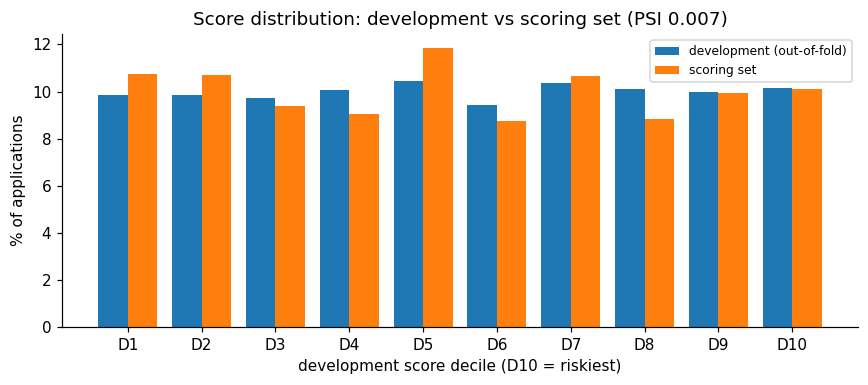

In [16]:
edges = np.quantile(p, np.linspace(0, 1, 11))
edges[0], edges[-1] = -np.inf, np.inf
d_dev = np.histogram(p, edges)[0] / len(p)
d_sc = np.histogram(ps, edges)[0] / len(ps)
psi_score = float(np.sum((d_sc - d_dev) * np.log(np.clip(d_sc, 1e-6, None) / np.clip(d_dev, 1e-6, None))))
d_ho = np.histogram(ph, edges)[0] / len(ph)
psi_hold = float(np.sum((d_ho - d_dev) * np.log(np.clip(d_ho, 1e-6, None) / np.clip(d_dev, 1e-6, None))))
print(f"Score PSI development -> holdout: {psi_hold:.4f} | development -> scoring set: {psi_score:.4f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(10)
ax.bar(x - .2, 100 * d_dev, .4, label="development (out-of-fold)")
ax.bar(x + .2, 100 * d_sc, .4, label="scoring set")
ax.set_xticks(x, [f"D{i + 1}" for i in x])
ax.set(xlabel="development score decile (D10 = riskiest)", ylabel="% of applications",
       title=f"Score distribution: development vs scoring set (PSI {psi_score:.3f})")
ax.legend(fontsize=8); plt.tight_layout(); fig.savefig(FIG / "11_score_psi.png", bbox_inches="tight"); plt.show()

**Result: stability.** The score PSI is 0.0060 from development to holdout and 0.0066 from development to the scoring set, both well
below 0.1. Although some individual inputs shift (Step 5), the **overall score distribution is stable**. This is the baseline
for production monitoring.

---

## 20. Recommendations

**1. Adopt a risk-based, three-band policy, but derive the cut-off from real economics.**
* **Set the thresholds from actual figures.** Finance and Risk should supply the net margin (*m*) and the loss on a
  payment-difficulty loan (*L*), giving *p\* = m/(m+L)*. Calibration makes this rule directly usable; Section 18.3 showed the
  empirical optimum matches it.
* **Under the central illustrative assumptions:** decline at p ≥ 0.25 (about 5–6% of applicants), review 0.144 ≤ p < 0.25
  (about 10%), and approve the rest. The approved book's difficulty rate falls from 8.07% to about 6.4%.

**2. Use the review band for verification, not automatic rejection.**
* The band holds about a quarter of all difficulty cases at a 19% rate.
* **Verify income and employment and check bureau exposure there**, or **offer a lower limit or a shorter term**.
* Prioritise the segments where ranking is weakest: short employment, recent late instalments, high credit-to-income and the
  not-employed.
* **Never decline on a single feature.** Section 19.4 showed that a debt-to-income rule would target the wrong applicants.

**3. Make better use of repayment history.**
* Recent behaviour (the last 12 months of instalment lateness) ranks risk better than all-time behaviour (Step 5), and
  history tables add about +0.02 ROC-AUC.
* **Keep these data flows reliable at decision time.**
* **Fix the bureau annuity and monthly-status reporting gaps** (Steps 4–5) so those features can be reconsidered.

**4. Govern the external scores as a critical dependency.**
* Without them, ROC-AUC drops by about 0.026 (Step 9).
* **Document their provenance, contractual availability, cost and refresh cycle.**
* **Monitor their missingness and distribution**, and keep the challenger and a no-external-score fallback model ready.

**5. Monitor the model continuously.**
* **Monthly:** score PSI (alert above 0.1, act above 0.25) and PSI of key inputs. `APP_CREDIT_TERM` and `APP_N_DOCUMENTS` already
  show major shifts.
* **Monthly:** approval, review and decline rates against the expected 84/10/6.
* **As outcomes mature:** calibration by score band, product, gender and age band, and ROC-AUC against the 0.788 holdout
  benchmark.
* **Retrain or recalibrate** if calibration gaps exceed about 1 pp or ROC-AUC drops by more than 0.02.

**6. Pilot before full deployment.**
* Random splits overstate future performance (Step 6), and this data contains only previously approved applicants.
* **Run a champion–challenger pilot on a share of live applications** against the current process.
* **Include a small, controlled approve-below-threshold sample** to observe outcomes for applicants the model would decline.
  This is the basis for future reject inference.

**7. Compliance review before launch.**
* **Confirm whether age may be used as an input.**
* **Review the gender and age calibration gaps** found in 19.5.
* **Approve the reason-code wording** derived from the explanations in 19.3.

### Limitations

| Limitation | Consequence |
|---|---|
| `TARGET` = early payment difficulty (X, Y undisclosed), not default | Losses are scenario-based; many difficulty cases cure |
| Only previously approved applicants (no rejected applicants, no reject inference) | Effects on the full applicant population are unknown; the pilot is needed |
| No calendar dates, so no out-of-time validation | Holdout performance is likely an upper bound |
| `SK_ID_CURR` is a loan, not a person | Repeat clients may sit in both training and validation folds, giving mildly optimistic estimates |
| No actual margins, losses or review costs | All money figures are illustrative; the review band is not priced |
| External scores of undocumented provenance | Strong, unexplained dependency |
| Some inputs shift in the scoring set | Monitoring is required, even though the overall score is stable |

**Stage status.** Steps 10–11 are complete. Remaining deliverables are Step 12 (repository and Git instructions) and Step 13
(a presentation of up to 10 slides in Bahasa Indonesia).